Dataset preview:
   TV_Advertising  Radio_Advertising      Sales
0      234.447254          78.853460  25.598852
1      137.274748          97.323510  24.266563
2      258.993397          52.570413  22.773282
3      212.236728          18.670263  10.078837
4       37.311431           6.323947  -1.989083

PEARSON CORRELATION
                   TV_Advertising  Radio_Advertising  Sales
TV_Advertising              1.000             -0.026  0.584
Radio_Advertising          -0.026              1.000  0.491
Sales                       0.584              0.491  1.000

SPEARMAN CORRELATION
                   TV_Advertising  Radio_Advertising  Sales
TV_Advertising              1.000             -0.019  0.594
Radio_Advertising          -0.019              1.000  0.485
Sales                       0.594              0.485  1.000

Pearson: TV advertising vs Sales: 0.584
Spearman: TV advertising vs Sales: 0.594


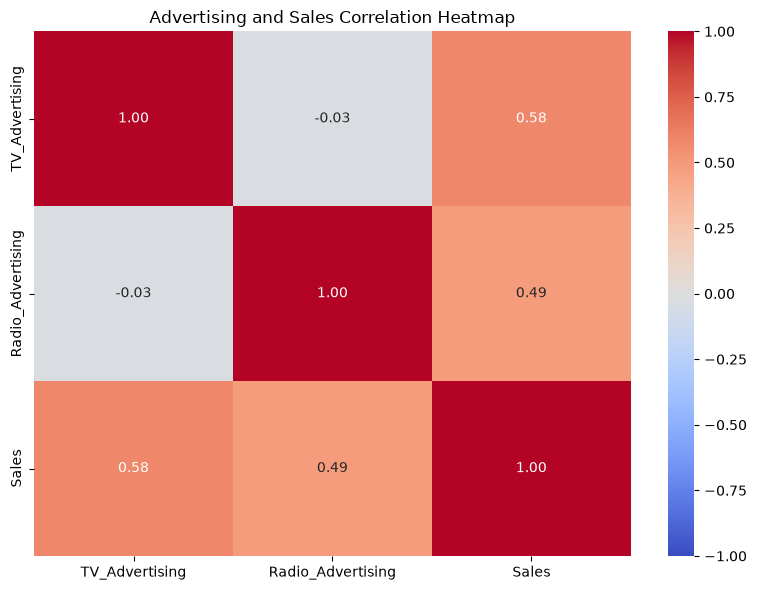

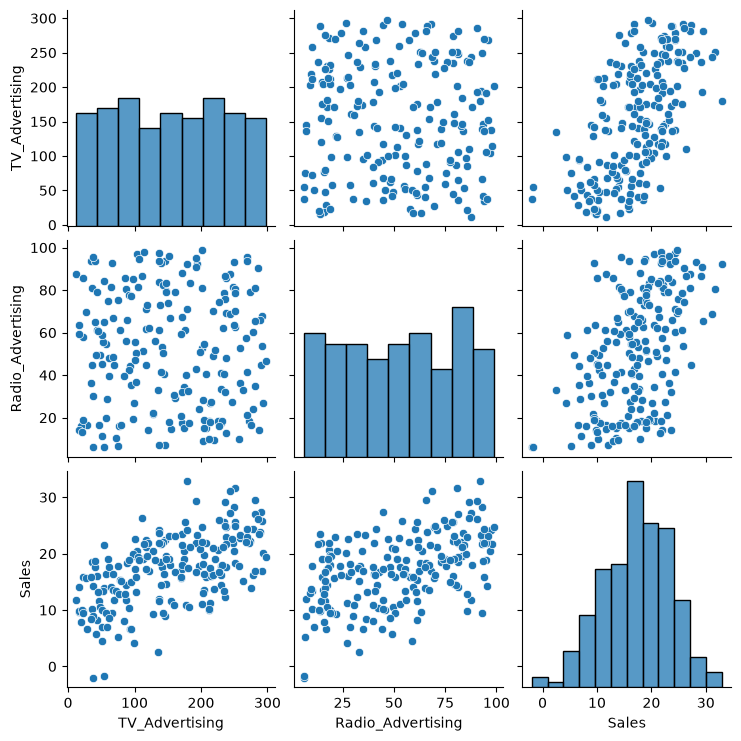


LINEAR REGRESSION RESULTS
Intercept: 3.79
TV_Advertising coefficient: 0.044
Radio_Advertising coefficient: 0.124

MODEL METRICS
R-squared (R²): 0.511
MAE: 3.468
RMSE: 4.261


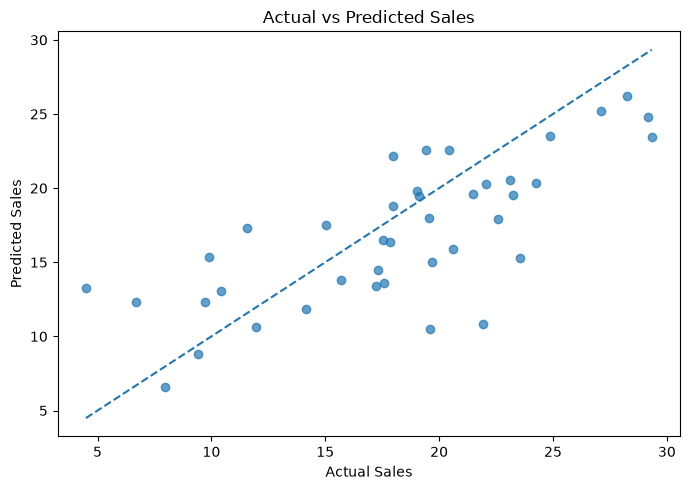

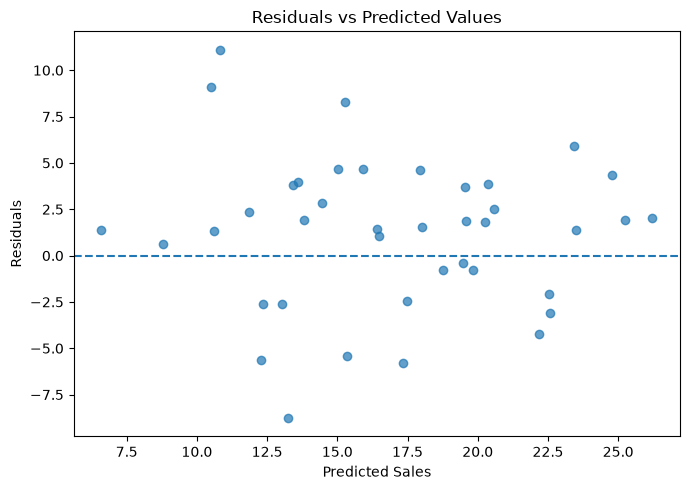

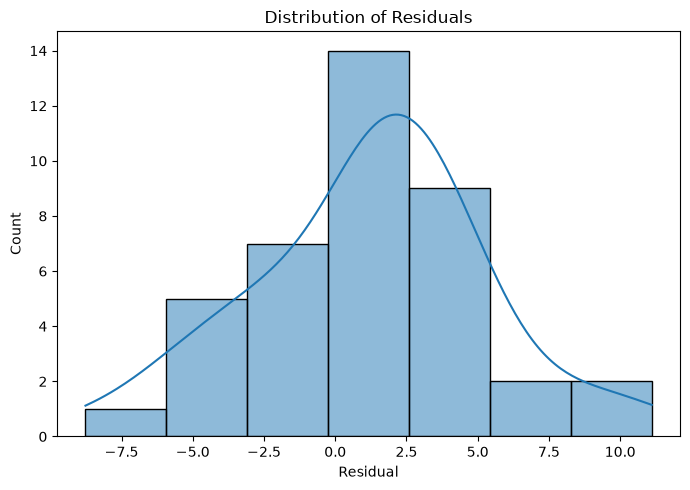

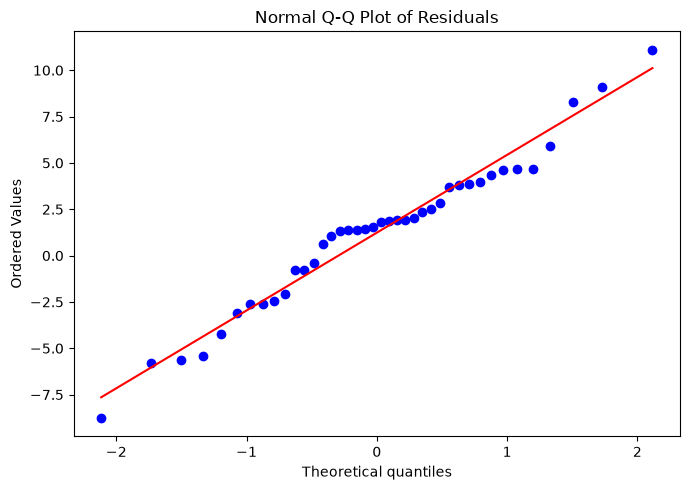


Analysis completed successfully!


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ==========================================
# 1. CREATE A SAMPLE DATASET
# ==========================================
rng = np.random.default_rng(42)
n = 200

tv = rng.uniform(10, 300, n)
radio = rng.uniform(5, 100, n)
noise = rng.normal(0, 4, n)

sales = 5 + 0.04 * tv + 0.12 * radio + noise

df = pd.DataFrame({
    "TV_Advertising": tv,
    "Radio_Advertising": radio,
    "Sales": sales
})

df.to_csv("advertising_sales.csv", index=False)

print("Dataset preview:")
print(df.head())

# ==========================================
# 2. PEARSON AND SPEARMAN CORRELATIONS
# ==========================================
print("\nPEARSON CORRELATION")
print(df.corr(method="pearson").round(3))

print("\nSPEARMAN CORRELATION")
print(df.corr(method="spearman").round(3))

print("\nPearson: TV advertising vs Sales:",
      round(df["TV_Advertising"].corr(df["Sales"]), 3))

print("Spearman: TV advertising vs Sales:",
      round(df["TV_Advertising"].corr(
          df["Sales"], method="spearman"), 3))

# ==========================================
# 3. CORRELATION HEATMAP
# ==========================================
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Advertising and Sales Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png")
plt.show()

# ==========================================
# 4. SCATTER MATRIX
# ==========================================
sns.pairplot(df, diag_kind="hist")
plt.savefig("scatter_matrix.png")
plt.show()

# ==========================================
# 5. BUILD LINEAR REGRESSION MODEL
# ==========================================
X = df[["TV_Advertising", "Radio_Advertising"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("\nLINEAR REGRESSION RESULTS")
print("Intercept:", round(model.intercept_, 3))

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature} coefficient: {coefficient:.3f}")

# ==========================================
# 6. MODEL EVALUATION
# ==========================================
r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("\nMODEL METRICS")
print(f"R-squared (R²): {r2:.3f}")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

# ==========================================
# 7. ACTUAL VS PREDICTED SALES
# ==========================================
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.7)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.tight_layout()
plt.savefig("actual_vs_predicted.png")
plt.show()

# ==========================================
# 8. RESIDUAL ANALYSIS
# ==========================================
residuals = y_test - predictions

# Residuals versus predicted values
plt.figure(figsize=(7, 5))
plt.scatter(predictions, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.tight_layout()
plt.savefig("residuals_plot.png")
plt.show()

# Residual distribution
plt.figure(figsize=(7, 5))
sns.histplot(residuals, kde=True)
plt.xlabel("Residual")
plt.title("Distribution of Residuals")
plt.tight_layout()
plt.savefig("residuals_distribution.png")
plt.show()

# Normal Q-Q plot
plt.figure(figsize=(7, 5))
from scipy import stats

stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Normal Q-Q Plot of Residuals")
plt.tight_layout()
plt.savefig("residuals_qq_plot.png")
plt.show()

# ==========================================
# 9. SAVE PREDICTIONS
# ==========================================
results = pd.DataFrame({
    "Actual_Sales": y_test.to_numpy(),
    "Predicted_Sales": predictions,
    "Residual": residuals.to_numpy()
})

results.to_csv("regression_predictions.csv", index=False)

print("\nAnalysis completed successfully!")

